# Distributions

**Notebook 1 of 5.** An exploratory analysis describes data: the histogram of a column,
its mean and its spread, and how strongly two columns move together. This repository asks
a sharper question about every pattern such an analysis finds: **could it just be
chance?**

Answering that takes two ideas before the tests themselves, one per notebook. This is the
first: a **distribution**, the smooth curve behind a histogram, and the fact that **the
area under that curve is a probability**. Every hypothesis test in this repository ends by
reading an area off a curve like this one. That area has a name, the *p-value*, and you
will compute your first one in `03_how_a_test_works.ipynb`.

By the end you should be able to:

- decide whether a column is discrete or continuous, and name a distribution that could
  model it.
- fit a normal distribution to a column and draw it over the histogram.
- find the probability of a value below, above or between thresholds.
- go the other way, and find the range that holds the middle 95 per cent.
- convert a value to a z-score, the number of standard deviations it sits from the mean.
- recognise when the normal curve is the wrong model.
- name the curve a test compares its result with: t, chi-square or F.

First the libraries this notebook needs.

In [1]:
# data analysis
import numpy as np
import pandas as pd

# visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# statistics: scipy.stats holds every distribution and every test used in this repository
from scipy import stats

sns.set_style("whitegrid")

Then the data: the **Palmer penguins**, 344 penguins of three species measured on three
islands in Antarctica between 2007 and 2009.

You will follow one group of them through the next three notebooks, the 68 **Chinstrap**
penguins. Here you describe how their body mass is distributed. In
`02_sampling_and_confidence_intervals.ipynb` you estimate the average Chinstrap body mass
and how sure you can be of it. In `03_how_a_test_works.ipynb` you test a claim about it.

In [2]:
# 344 penguins, one row each
df_penguins = pd.read_csv("data/penguins.csv")
df_penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [3]:
# keep only the Chinstrap penguins
chinstrap = df_penguins[df_penguins["species"] == "Chinstrap"]
chinstrap["body_mass_g"].describe()

count      68.000000
mean     3733.088235
std       384.335081
min      2700.000000
25%      3487.500000
50%      3700.000000
75%      3950.000000
max      4800.000000
Name: body_mass_g, dtype: float64

Two penguins in the full dataset have no measurements at all, but neither is a Chinstrap,
so all 68 rows here are complete.

## 1. From histogram to curve

A histogram of 68 penguins is lumpy. Weigh a different 68 Chinstraps and the bars would
come out differently, although the penguins are the same kind of animal. What stays the
same is the **shape underneath**: roughly where the weights are centred, how far they
spread, and whether they trail off to one side. A **distribution** is a mathematical
description of that shape.

Which distribution to reach for depends first on what kind of column you have: a
**discrete** column counts things and takes whole values, a **continuous** one can take any
value in a range. Three distributions cover most of what you will see:

| The column... | Type | Distribution |
| :--- | :--- | :--- |
| counts successes in a fixed number of tries, like patients cured out of 20 | discrete | binomial |
| counts events in a fixed stretch of time, like support calls per hour | discrete | Poisson |
| measures something that can take any value in a range, like a height or a weight | continuous | often normal |

Body mass is a measurement, so it is continuous. The measurements of one species of animal
are very often bell-shaped, symmetric around a typical value, which makes the **normal
distribution** the natural candidate.

The normal distribution has exactly two parameters: the **mean** $\mu$, where the bell is
centred, and the **standard deviation** $\sigma$, how wide it is. We do not know the true
values for all Chinstrap penguins, so we use the mean and standard deviation of our 68.

In [4]:
mass = chinstrap["body_mass_g"]

# the two numbers that pin down a normal curve
mean_mass = mass.mean()
std_mass = mass.std()

print(f"mean              : {mean_mass:.1f} g")
print(f"standard deviation: {std_mass:.1f} g")

mean              : 3733.1 g
standard deviation: 384.3 g


To lay a curve over a histogram, the two must be drawn on the same scale.
`stat="density"` rescales the bars so that their total area is 1, which is the scale a
distribution curve lives on. `stats.norm.pdf` then gives the height of the normal curve at
every point we ask about.

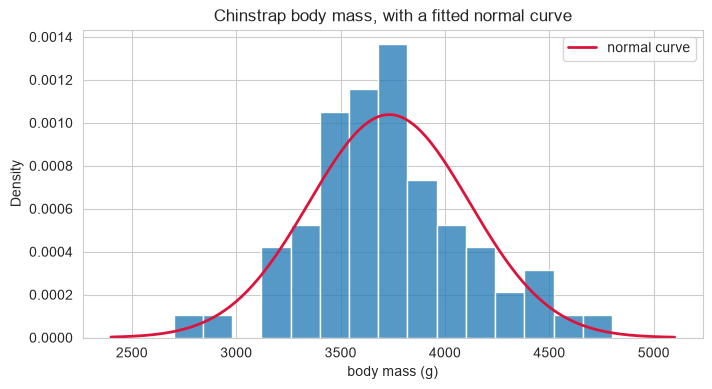

In [5]:
# 200 evenly spaced weights, a little beyond the lightest and heaviest penguin
x = np.linspace(mass.min() - 300, mass.max() + 300, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# density scale: the bars' total area is 1
sns.histplot(mass, stat="density", bins=15, ax=ax)

# the normal curve with our mean and standard deviation
ax.plot(x, stats.norm.pdf(x, loc=mean_mass, scale=std_mass), color="crimson", linewidth=2,
        label="normal curve")

ax.set_title("Chinstrap body mass, with a fitted normal curve")
ax.set_xlabel("body mass (g)")
ax.legend()
plt.show()

The curve follows the bars reasonably well: one peak near the mean, and a fall-off that is
about equal on both sides. It is not a perfect match and never will be with 68 penguins,
but it is a fair summary of the shape.

> **Note.** The height of the curve is a *density*, not a probability. The probability
> that a penguin weighs exactly 3,733.0000 g is zero. Probabilities belong to **ranges**
> of values, which is the next section.

> **Exercise:**
>
> Do the same for the Chinstraps' **flipper length**, `flipper_length_mm`. Compute its
> mean and standard deviation, then plot the histogram on the density scale with the
> fitted normal curve on top. Is the normal curve a fair model for it?

mean              : 195.8 mm
standard deviation: 7.1 mm


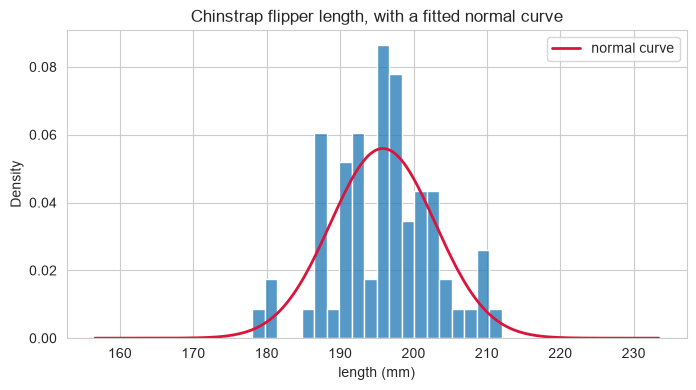

In [16]:
length = chinstrap["flipper_length_mm"]
mean_length = length.mean()
std_length = length.std()

print(f"mean              : {mean_length:.1f} mm")
print(f"standard deviation: {std_length:.1f} mm")

x = np.linspace(length.min() - 3 * std_length, length.max() + 3 * std_length, 200)

fig, ax = plt.subplots(figsize=(8, 4))

# density scale: the bars' total area is 1
sns.histplot(length, stat="density", bins=20, ax=ax)

# the normal curve with our mean and standard deviation
ax.plot(x, stats.norm.pdf(x, loc=mean_length, scale=std_length), color="crimson", linewidth=2,
        label="normal curve")

ax.set_title("Chinstrap flipper length, with a fitted normal curve")
ax.set_xlabel("length (mm)")
ax.legend()
plt.show()

## 2. The area under the curve is a probability

Once the curve is fitted, a question like *"how likely is a Chinstrap to weigh less than
3,500 g?"* has a precise answer: it is the **area under the curve to the left of 3,500**.
The whole area is 1, so any part of it is a share between 0 and 1.

`stats.norm.cdf`, the **cumulative distribution function**, returns exactly that area:
everything to the left of the value you give it.

In [ ]:
threshold = 3500

# area to the left of the threshold, under the fitted curve
p_below_model = stats.norm.cdf(threshold, loc=mean_mass, scale=std_mass)

# the same question asked of the 68 penguins directly
p_below_data = (mass < threshold).mean()

print(f"model: {p_below_model:.1%} of Chinstraps weigh less than {threshold} g")
print(f"data : {p_below_data:.1%} ({(mass < threshold).sum()} of {len(mass)} penguins)")

In [ ]:
x = np.linspace(mass.min() - 300, mass.max() + 300, 200)
y = stats.norm.pdf(x, loc=mean_mass, scale=std_mass)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, color="crimson", linewidth=2)

# shade the area the cdf just measured
ax.fill_between(x, y, where=(x <= threshold), color="crimson", alpha=0.3,
                label=f"area = {p_below_model:.3f}")

ax.axvline(threshold, color="black", linestyle="--")
ax.set_title(f"P(body mass < {threshold} g) under the fitted normal curve")
ax.set_xlabel("body mass (g)")
ax.set_ylabel("density")
ax.legend()
plt.show()

The model says 27 per cent, and 17 of the 68 penguins, 25 per cent, actually weigh less
than 3,500 g. The two agree closely, which is what a well-fitting model should do. The
model's answer is also *smoother*: it does not jump when one penguin moves across the line.

Two more areas follow from the same function:

- **Above** a value is everything that is not below it: `1 - stats.norm.cdf(value, ...)`.
- **Between** two values is the area left of the upper one minus the area left of the
  lower one: `stats.norm.cdf(upper, ...) - stats.norm.cdf(lower, ...)`.

> **Exercise:**
>
> Using the normal curve you fitted to Chinstrap flipper length:
>
> 1. What share of Chinstraps does the model say have flippers **longer than 200 mm**?
>    Compare it with the share in the data.
> 2. What share does it put **between 190 and 200 mm**?

<details><summary>
Click here for a hint...
</summary>

You already have `mean_flipper` and `std_flipper` from the last exercise. Pass them as
`loc` and `scale`. For the share in the data, `(flipper > 200).mean()` works the same way
as the body-mass example above.
</details>

In [10]:
# your code: longer than 200 mm, model and data
threshold = 200

# model: area to the RIGHT of 200 mm = everything minus the area to the left
p_above_model = 1 - stats.norm.cdf(threshold, loc=mean_length, scale=std_length)

# data: share of the 68 penguins whose flipper is longer than 200 mm
p_above_data = (length > threshold).mean()

print(f"model: {p_above_model:.1%} of Chinstraps have flippers longer than {threshold} mm")
print(f"data : {p_above_data:.1%} ({(length > threshold).sum()} of {len(length)} penguins)")


model: 27.9% of Chinstraps have flippers longer than 200 mm
data : 26.5% (18 of 68 penguins)


In [11]:
# your code: between 190 and 200 mm
lower, upper = 190, 200

# model: area left of the upper bound minus area left of the lower bound
p_between_model = (stats.norm.cdf(upper, loc=mean_length, scale=std_length)
                   - stats.norm.cdf(lower, loc=mean_length, scale=std_length))

# data: share of penguins in the range (between() includes both bounds)
in_range = length.between(lower, upper)
p_between_data = in_range.mean()

print(f"model: {p_between_model:.1%} of Chinstraps have flippers between {lower} and {upper} mm")
print(f"data : {p_between_data:.1%} ({in_range.sum()} of {len(length)} penguins)")


model: 51.4% of Chinstraps have flippers between 190 and 200 mm
data : 55.9% (38 of 68 penguins)


## 3. Going backwards: from a probability to a value

`cdf` takes a value and returns an area. Its inverse, `stats.norm.ppf` (the *percent point
function*), takes an area and returns the value that cuts it off.

The question it answers most often is: **which range holds the middle 95 per cent?** Cut
2.5 per cent off each tail, and read off the two values where the cuts fall.

In [ ]:
# the values that leave 2.5% of the area in each tail
lower, upper = stats.norm.ppf([0.025, 0.975], loc=mean_mass, scale=std_mass)
print(f"middle 95% of Chinstrap body mass: {lower:.0f} g to {upper:.0f} g")

# how many of our penguins actually fall inside that range?
inside = mass.between(lower, upper)
print(f"penguins inside: {inside.sum()} of {len(mass)} ({inside.mean():.1%})")

The model puts the middle 95 per cent of Chinstraps between about 2,980 g and 4,486 g, and
63 of our 68 penguins fall inside it.

### z-scores and the number 1.96

A distance in grams only means something if you know how spread out the weights are. The
**z-score** removes the units by counting in standard deviations instead:

$$
z = \frac{x - \mu}{\sigma}
$$

A z-score of 0 is exactly average; +2 is two standard deviations above it. Converting every
value this way turns any normal curve into the same one, the **standard normal**, with mean
0 and standard deviation 1. That is `stats.norm` with no `loc` or `scale` at all.

Ask the standard normal where its middle 95 per cent ends:

In [ ]:
# no loc or scale: the standard normal, mean 0 and standard deviation 1
z_crit = stats.norm.ppf(0.975)
print(f"the middle 95% of any normal distribution lies within {z_crit:.2f} "
      "standard deviations of its mean")

**Remember 1.96.** It is true of every normal distribution, whatever it measures, and it
comes back twice in this repository: in `02_sampling_and_confidence_intervals.ipynb` it builds a
confidence interval, and in `03_how_a_test_works.ipynb` it is the line a test result has to
cross to count as surprising.

Now take a heavy Chinstrap, 4,500 g, and ask how unusual it is.

In [ ]:
heavy = 4500

# how many standard deviations above the mean?
z_heavy = (heavy - mean_mass) / std_mass
print(f"z-score of a {heavy} g Chinstrap: {z_heavy:.2f}")

# the area beyond it, asked two ways: on the grams scale and on the z scale
print(f"heavier than this, grams scale: {1 - stats.norm.cdf(heavy, loc=mean_mass, scale=std_mass):.2%}")
print(f"heavier than this, z scale    : {1 - stats.norm.cdf(z_heavy):.2%}")

A 4,500 g Chinstrap is 2.0 standard deviations above the mean, and the model says only
about 2.3 per cent of Chinstraps are heavier. Both scales give the same area, because the
z-score only relabels the axis.

This is exactly how a hypothesis test will judge a result in notebook 03: turn it into
*how many standard units away from what we expected*, then measure *how much area lies
beyond it*. A small area means a surprising result.

> **Exercise:**
>
> Back to Chinstrap flipper length.
>
> 1. Which range holds the middle 95 per cent of flipper lengths, according to the model?
> 2. What is the z-score of a Chinstrap with a 210 mm flipper, and what share of
>    Chinstraps does the model say have a flipper at least that long?

In [12]:
# your code: the middle 95% of flipper lengths
# the values that leave 2.5% of the area in each tail
lower, upper = stats.norm.ppf([0.025, 0.975], loc=mean_length, scale=std_length)
print(f"middle 95% of Chinstrap flipper length: {lower:.1f} mm to {upper:.1f} mm")

# how many of our penguins actually fall inside that range?
inside = length.between(lower, upper)
print(f"penguins inside: {inside.sum()} of {len(length)} ({inside.mean():.1%})")


middle 95% of Chinstrap flipper length: 181.8 mm to 209.8 mm
penguins inside: 61 of 68 (89.7%)


In [17]:
# your code: z-score of a 210 mm flipper, and the share at least that long
# your code: z-score of a 210 mm flipper, and the share at least that long
long = 210

# how many standard deviations above the mean?
z_long = (long - mean_length) / std_length
print(f"z-score of a {long} g Chinstrap: {z_long:.2f}")

# the area beyond it, asked two ways: on the grams scale and on the z scale
print(f"longer than this, mm scale: {1 - stats.norm.cdf(long, loc=mean_length, scale=std_length):.2%}")
print(f"longer than this, z scale    : {1 - stats.norm.cdf(z_long):.2%}")

z-score of a 210 g Chinstrap: 1.99
longer than this, mm scale: 2.34%
longer than this, z scale    : 2.34%


## 4. When the normal curve is the wrong model

Every calculation so far trusted the fitted curve. That trust was earned by looking at the
histogram first, and by modelling **one species** at a time. The next exercise shows what
happens without that care.

> **Exercise:**
>
> Take the body mass of **all** the penguins, every species together.
>
> 1. Drop the two missing values, fit a normal curve, and plot it over the histogram as in
>    section 1.
> 2. Ask the model what share of penguins weigh less than 3,000 g, and compare it with the
>    data. Then do the same for less than 2,700 g.
> 3. In a sentence or two: why does the model get these wrong?

<details><summary>
Click here for a hint...
</summary>

`df_penguins["body_mass_g"].dropna()` gives the 342 weights. For question 3, colour the
histogram by species: `sns.histplot(data=df_penguins, x="body_mass_g", hue="species",
multiple="stack")`.
</details>

In [13]:
# your code: z-score of a 210 mm flipper, and the share at least that long
long_flipper = 210

# how many standard deviations above the mean?
z_long = (long_flipper - mean_length) / std_length
print(f"z-score of a {long_flipper} mm flipper: {z_long:.2f}")

# the area beyond it, asked two ways: on the mm scale and on the z scale
print(f"at least this long, mm scale: {1 - stats.norm.cdf(long_flipper, loc=mean_length, scale=std_length):.2%}")
print(f"at least this long, z scale : {1 - stats.norm.cdf(z_long):.2%}")

# for comparison: what the 68 penguins actually show
print(f"at least this long, data    : {(length >= long_flipper).mean():.2%} "
      f"({(length >= long_flipper).sum()} of {len(length)} penguins)")

z-score of a 210 mm flipper: 1.99
at least this long, mm scale: 2.34%
at least this long, z scale : 2.34%
at least this long, data    : 5.88% (4 of 68 penguins)


In [14]:
# your code: compare model and data below 3,000 g and below 2,700 g
# (from the previous cell) all 342 weights, every species together
all_mass = df_penguins["body_mass_g"].dropna()
mean_all = all_mass.mean()
std_all = all_mass.std()

for threshold in [3000, 2700]:
    # model: area to the left of the threshold
    p_model = stats.norm.cdf(threshold, loc=mean_all, scale=std_all)

    # data: share of penguins lighter than the threshold
    p_data = (all_mass < threshold).mean()

    print(f"below {threshold} g -> model: {p_model:.1%}, "
          f"data: {p_data:.1%} ({(all_mass < threshold).sum()} of {len(all_mass)} penguins)")

below 3000 g -> model: 6.7%, data: 2.6% (9 of 342 penguins)
below 2700 g -> model: 3.1%, data: 0.0% (0 of 342 penguins)


In [ ]:
# your code (optional): colour the histogram by species to see why

<details><summary>
Click here to compare your answer to question 3...
</summary>

The model puts about 6.7 per cent of penguins below 3,000 g, where the data has 2.6 per
cent, and about 3 per cent below 2,700 g, where the data has none: the lightest penguin
weighs exactly 2,700 g.

The data is not one bell but a **mixture**. Adelie and Chinstrap penguins weigh about
3,700 g on average, Gentoo penguins about 5,100 g. Pooled, they make a lopsided shape with
a second hump on the right. A single normal curve cannot bend to fit that, so it stretches
wide to cover both humps and spills its left tail into weights no penguin has.
</details>

The lesson carries into every test that follows: **look at the histogram before you trust the
curve.** The tests in notebooks 03 to 05 make assumptions about the shape of the data, and
checking them starts with a plot.

## 5. Curves for test results

Every curve so far described **data**: penguin weights here, and counts in the table of
section 1. Hypothesis testing needs a second kind of curve. A test boils a whole dataset
down to **one number**, its *test statistic*, and then asks where that number falls on a
curve describing how it would vary by chance alone.

You never fit these curves to a column, and scipy uses them for you. But three of them do
all the work in this repository, so it is worth seeing them once before they matter:

| Curve | What the test statistic measures | Where you meet it |
| :--- | :--- | :--- |
| **t** | how far an average sits from a claimed value, in standard errors | notebooks 02 and 03, then the t-test and the correlation test in 04 |
| **chi-square** | how far the counts in a table sit from the counts expected if two columns were unrelated | the chi-square test in 04 |
| **F** | how far apart several group averages sit, compared with the spread inside each group | ANOVA in 04 |

Each has a shape parameter called the **degrees of freedom**, set by how much data went into
the statistic. The plot shows every curve at two settings; the solid line in each panel is
the setting the worked examples in notebooks 03 and 04 use.

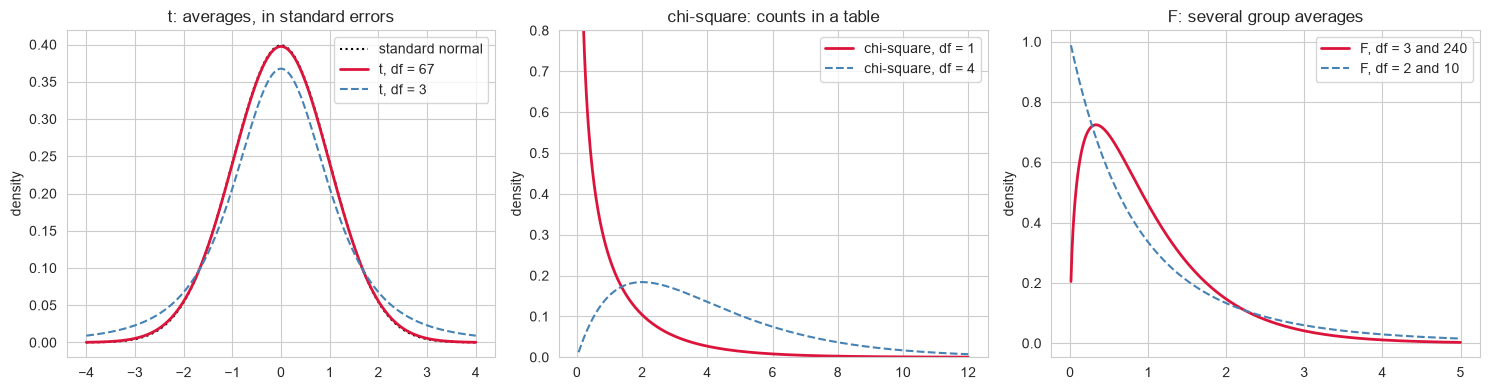

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# t: bell-shaped around 0, like the standard normal (dotted) but with heavier tails
x = np.linspace(-4, 4, 400)
axes[0].plot(x, stats.norm.pdf(x), color="black", linestyle=":", label="standard normal")
axes[0].plot(x, stats.t.pdf(x, df=67), color="crimson", linewidth=2, label="t, df = 67")
axes[0].plot(x, stats.t.pdf(x, df=3), color="steelblue", linestyle="--", label="t, df = 3")
axes[0].set_title("t: averages, in standard errors")

# chi-square: built from squared distances, so it starts at 0 and never goes negative
x = np.linspace(0.05, 12, 400)
axes[1].plot(x, stats.chi2.pdf(x, df=1), color="crimson", linewidth=2, label="chi-square, df = 1")
axes[1].plot(x, stats.chi2.pdf(x, df=4), color="steelblue", linestyle="--",
             label="chi-square, df = 4")
axes[1].set_ylim(0, 0.8)
axes[1].set_title("chi-square: counts in a table")

# F: a ratio of two spreads, so it also starts at 0; it takes two degrees of freedom
x = np.linspace(0.01, 5, 400)
axes[2].plot(x, stats.f.pdf(x, dfn=3, dfd=240), color="crimson", linewidth=2,
             label="F, df = 3 and 240")
axes[2].plot(x, stats.f.pdf(x, dfn=2, dfd=10), color="steelblue", linestyle="--",
             label="F, df = 2 and 10")
axes[2].set_title("F: several group averages")

for ax in axes:
    ax.set_ylabel("density")
    ax.legend()

plt.tight_layout()
plt.show()

Three things to take from the picture:

- **t** is the standard normal's close relative: centred on 0, symmetric, with heavier tails
  when the degrees of freedom are few. At 67, the setting notebook 03 uses for the 68
  Chinstraps, it is almost indistinguishable from the normal curve.
- **chi-square** and **F** start at 0 and trail off to the right. Their statistics are built
  from squared distances and ratios of spreads, so they can never be negative, and only a
  **large** value is surprising.
- **Areas work exactly as in section 2.** `stats.t`, `stats.chi2` and `stats.f` all have
  `cdf` and `ppf`, just like `stats.norm`. Every p-value in this repository is an area under
  one of these three curves.

## Wrapping up

In this notebook you:

- matched a column to a distribution by its type and its shape.
- fitted a normal curve to Chinstrap body mass with two numbers, the mean and the standard
  deviation.
- read probabilities off that curve as areas, with `stats.norm.cdf`.
- went back from an area to a value with `stats.norm.ppf`, and met 1.96.
- measured how unusual a value is with its z-score.
- saw a normal curve fail on data that is really a mixture of three groups.
- met the three curves that tests compare their results with: t, chi-square and F.

Everything here described **single penguins**. The next notebook asks about the **average**
penguin: if you had weighed a different 68 Chinstraps, how much would the mean have
changed? The answer is another normal curve, and 1.96 comes straight back.

## References & Further Reading

- [**scipy.stats.norm**](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html):
  The normal distribution, with `pdf`, `cdf`, `ppf` and the rest of its methods.
  [`scipy.stats.t`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html),
  [`chi2`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html) and
  [`f`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f.html)
  have the same methods.
- [**Seeing Theory: Probability Distributions**](https://seeing-theory.brown.edu/probability-distributions/index.html):
  Interactive visual explanations of the distributions in the table in section 1.
- [**seaborn.histplot**](https://seaborn.pydata.org/generated/seaborn.histplot.html):
  The histogram used throughout, including the `stat="density"` option.
- [**palmerpenguins**](https://allisonhorst.github.io/palmerpenguins/): Where the dataset
  comes from, collected by Dr Kristen Gorman at Palmer Station, Antarctica.